In [1]:
import importlib.metadata as metadata

for package in ["numpy", "pandas", "matplotlib", "rdflib"]:
    print(package, metadata.version(package))

numpy 2.5.4
pandas 3.1.1
matplotlib 3.11.2
rdflib 7.6.0


In [2]:
import sys
print("Python:", sys.version)

Python: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]


In [3]:
import rdflib
print("RDFLib:", rdflib.__version__)

RDFLib: 7.6.0


In [4]:
import numpy
print("NumPy:", numpy.__version__)

NumPy: 2.5.4


In [5]:
import matplotlib.pyplot as plt
print("Matplotlib imported successfully!")

Matplotlib imported successfully!


In [6]:
import sys
import rdflib
import pandas as pd
import matplotlib.pyplot as plt

rdflib.NORMALIZE_LITERALS = False

from rdflib import Graph
from pathlib import Path

In [7]:
from pathlib import Path

dataset_folder = Path("../data/BPDP_Dataset")

train_true = dataset_folder / "Train" / "True"
train_false = dataset_folder / "Train" / "False"
test_true = dataset_folder / "Test" / "True"
test_false = dataset_folder / "Test" / "False"

print("Dataset folders configured successfully.")

Dataset folders configured successfully.


### Dataset Structure and Class Distribution

The BPDP dataset is organised into training and testing subsets, each containing True and False categories. The training set contains 100 True and 100 False RDF files, while the test set contains 103 True and 103 False RDF files.

In total, the dataset contains 406 RDF files, with 203 files in each class. This indicates a balanced class distribution across the training and testing subsets.

In [8]:
# Count the Turtle files in each dataset folder

print("Train True:", len(list(train_true.glob("*.ttl"))))
print("Train False:", len(list(train_false.glob("*.ttl"))))
print("Test True:", len(list(test_true.glob("*.ttl"))))
print("Test False:", len(list(test_false.glob("*.ttl"))))

Train True: 100
Train False: 100
Test True: 103
Test False: 103


### RDF Triple Statistics

The RDF graphs were analysed to calculate the total, average, minimum and maximum number of triples per file.

The training True and False groups each contain 1,976 triples, with an average of 19.76 triples per file. The test True and False groups each contain 2,024 triples, with an average of approximately 19.65 triples per file.

The minimum graph size is 14 triples, while the maximum is 20 triples. These results show that the RDF graphs have relatively consistent sizes across all four dataset groups.

In [9]:
from rdflib import Graph
import pandas as pd

# Avoid automatic conversion of unusual date literals
rdflib.NORMALIZE_LITERALS = False

# Organise the four dataset folders
dataset_groups = [
    ("Train True", train_true),
    ("Train False", train_false),
    ("Test True", test_true),
    ("Test False", test_false)
]

# Store the results for later analysis
all_results = []

# Analyse each dataset group
for group_name, folder in dataset_groups:

    files = sorted(folder.glob("*.ttl"))

    print("\nDataset group:", group_name)
    print("Number of files:", len(files))

    # First, inspect one example file
    if files:
        example_file = files[0]

        example_graph = Graph()
        example_graph.parse(str(example_file), format="turtle")

        print("\nExample file:", example_file.name)
        print("Triples in example file:", len(example_graph))

    # Now analyse every file in the group
    triple_counts = []

    for file in files:
        graph = Graph()
        graph.parse(str(file), format="turtle")

        number_of_triples = len(graph)
        triple_counts.append(number_of_triples)

        all_results.append({
            "Group": group_name,
            "File": file.name,
            "Triples": number_of_triples
        })

    # Display summary statistics
    if triple_counts:
        print("\nStatistics for all files:")
        print("Total triples:", sum(triple_counts))
        print("Average triples:", round(sum(triple_counts) / len(triple_counts), 2))
        print("Minimum triples:", min(triple_counts))
        print("Maximum triples:", max(triple_counts))

    print("-----------------------------------")

# Convert the results into a table
results_df = pd.DataFrame(all_results)

print("\nComplete dataset summary:")
display(results_df.groupby("Group")["Triples"].agg(
    ["count", "sum", "mean", "min", "max"]
))

Failed to convert Literal lexical form to value. Datatype=http://www.w3.org/2001/XMLSchema#date, Converter=<function parse_xsd_date at 0x000001F11373F100>
Traceback (most recent call last):
  File "c:\Users\asus\Desktop\Semantic_Project\small-language-models-shallow-knowledge\.venv\Lib\site-packages\rdflib\term.py", line 2262, in _castLexicalToPython
    return conv_func(lexical)  # type: ignore[arg-type]
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\asus\Desktop\Semantic_Project\small-language-models-shallow-knowledge\.venv\Lib\site-packages\rdflib\xsd_datetime.py", line 587, in parse_xsd_date
    return parse_date(date_string if not minus else ("-" + date_string))
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
ValueError: Invalid isoformat string: '1846-4-4'
Failed to convert Literal lexical form to value. Datatype=http://www.w3.org/2001/XMLSchema#date, Converter=<function parse_xsd_date at 0x000001F11373F100>
Traceback (most recent call last):
  File "c:\U


Dataset group: Train True
Number of files: 100

Example file: birth_0.ttl
Triples in example file: 20


Failed to convert Literal lexical form to value. Datatype=http://www.w3.org/2001/XMLSchema#date, Converter=<function parse_xsd_date at 0x000001F11373F100>
Traceback (most recent call last):
  File "c:\Users\asus\Desktop\Semantic_Project\small-language-models-shallow-knowledge\.venv\Lib\site-packages\rdflib\term.py", line 2262, in _castLexicalToPython
    return conv_func(lexical)  # type: ignore[arg-type]
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\asus\Desktop\Semantic_Project\small-language-models-shallow-knowledge\.venv\Lib\site-packages\rdflib\xsd_datetime.py", line 587, in parse_xsd_date
    return parse_date(date_string if not minus else ("-" + date_string))
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
ValueError: Invalid isoformat string: '1877-11-2'
Failed to convert Literal lexical form to value. Datatype=http://www.w3.org/2001/XMLSchema#date, Converter=<function parse_xsd_date at 0x000001F11373F100>
Traceback (most recent call last):
  File "c:\


Statistics for all files:
Total triples: 1976
Average triples: 19.76
Minimum triples: 14
Maximum triples: 20
-----------------------------------

Dataset group: Train False
Number of files: 100

Example file: birth_103.ttl
Triples in example file: 20


Failed to convert Literal lexical form to value. Datatype=http://www.w3.org/2001/XMLSchema#date, Converter=<function parse_xsd_date at 0x000001F11373F100>
Traceback (most recent call last):
  File "c:\Users\asus\Desktop\Semantic_Project\small-language-models-shallow-knowledge\.venv\Lib\site-packages\rdflib\term.py", line 2262, in _castLexicalToPython
    return conv_func(lexical)  # type: ignore[arg-type]
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\asus\Desktop\Semantic_Project\small-language-models-shallow-knowledge\.venv\Lib\site-packages\rdflib\xsd_datetime.py", line 587, in parse_xsd_date
    return parse_date(date_string if not minus else ("-" + date_string))
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
ValueError: Invalid isoformat string: '1903-6-25'
Failed to convert Literal lexical form to value. Datatype=http://www.w3.org/2001/XMLSchema#date, Converter=<function parse_xsd_date at 0x000001F11373F100>
Traceback (most recent call last):
  File "c:\


Statistics for all files:
Total triples: 1976
Average triples: 19.76
Minimum triples: 14
Maximum triples: 20
-----------------------------------

Dataset group: Test True
Number of files: 103

Example file: birth_100.ttl
Triples in example file: 20


Failed to convert Literal lexical form to value. Datatype=http://www.w3.org/2001/XMLSchema#date, Converter=<function parse_xsd_date at 0x000001F11373F100>
Traceback (most recent call last):
  File "c:\Users\asus\Desktop\Semantic_Project\small-language-models-shallow-knowledge\.venv\Lib\site-packages\rdflib\term.py", line 2262, in _castLexicalToPython
    return conv_func(lexical)  # type: ignore[arg-type]
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\asus\Desktop\Semantic_Project\small-language-models-shallow-knowledge\.venv\Lib\site-packages\rdflib\xsd_datetime.py", line 587, in parse_xsd_date
    return parse_date(date_string if not minus else ("-" + date_string))
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
ValueError: Invalid isoformat string: '1952-8-21'
Failed to convert Literal lexical form to value. Datatype=http://www.w3.org/2001/XMLSchema#date, Converter=<function parse_xsd_date at 0x000001F11373F100>
Traceback (most recent call last):
  File "c:\


Statistics for all files:
Total triples: 2024
Average triples: 19.65
Minimum triples: 14
Maximum triples: 20
-----------------------------------

Dataset group: Test False
Number of files: 103

Example file: birth_154.ttl
Triples in example file: 20


Failed to convert Literal lexical form to value. Datatype=http://www.w3.org/2001/XMLSchema#date, Converter=<function parse_xsd_date at 0x000001F11373F100>
Traceback (most recent call last):
  File "c:\Users\asus\Desktop\Semantic_Project\small-language-models-shallow-knowledge\.venv\Lib\site-packages\rdflib\term.py", line 2262, in _castLexicalToPython
    return conv_func(lexical)  # type: ignore[arg-type]
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\asus\Desktop\Semantic_Project\small-language-models-shallow-knowledge\.venv\Lib\site-packages\rdflib\xsd_datetime.py", line 587, in parse_xsd_date
    return parse_date(date_string if not minus else ("-" + date_string))
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
ValueError: Invalid isoformat string: '1816-7-14'
Failed to convert Literal lexical form to value. Datatype=http://www.w3.org/2001/XMLSchema#date, Converter=<function parse_xsd_date at 0x000001F11373F100>
Traceback (most recent call last):
  File "c:\


Statistics for all files:
Total triples: 2024
Average triples: 19.65
Minimum triples: 14
Maximum triples: 20
-----------------------------------

Complete dataset summary:


,count,sum,mean,min,max
Group,,,,,
Test False,103,2024,19.650485,14,20
Test True,103,2024,19.650485,14,20
Train False,100,1976,19.760000,14,20
Train True,100,1976,19.760000,14,20


In [10]:
import re

# Find dates that do not follow YYYY-MM-DD format

date_pattern = re.compile(r"^\d{4}-\d{2}-\d{2}$")

files_with_date_issues = []
total_date_issues = 0

for group_name, folder in dataset_groups:

    for file in folder.glob("*.ttl"):

        with open(file, "r", encoding="utf-8") as f:
            for line_number, line in enumerate(f, start=1):

                if "^^xsd:date" in line:

                    date_values = re.findall(r'"([^"]+)"', line)

                    for date_value in date_values:

                        if not date_pattern.match(date_value):
                            total_date_issues += 1

                            files_with_date_issues.append({
                                "Group": group_name,
                                "File": file.name,
                                "Line": line_number,
                                "Date": date_value
                            })

print("Total date-format issues:", total_date_issues)
print("Files containing date-format issues:",
      len(set(item["File"] for item in files_with_date_issues)))

for item in files_with_date_issues[:10]:
    print(item)

issues_df = pd.DataFrame(files_with_date_issues)

print("Date-format issues by dataset group:")

display(
    issues_df.groupby("Group").agg(
        Total_Issues=("Date", "count"),
        Files_Affected=("File", "nunique")
    )
)

Total date-format issues: 644
Files containing date-format issues: 322
{'Group': 'Train True', 'File': 'birth_10.ttl', 'Line': 9, 'Date': '1846-4-4'}
{'Group': 'Train True', 'File': 'birth_10.ttl', 'Line': 10, 'Date': '1846-4-4'}
{'Group': 'Train True', 'File': 'birth_11.ttl', 'Line': 20, 'Date': '-525-0-0'}
{'Group': 'Train True', 'File': 'birth_11.ttl', 'Line': 21, 'Date': '-525-0-0'}
{'Group': 'Train True', 'File': 'birth_12.ttl', 'Line': 14, 'Date': '1864-8-11'}
{'Group': 'Train True', 'File': 'birth_12.ttl', 'Line': 15, 'Date': '1864-8-11'}
{'Group': 'Train True', 'File': 'birth_14.ttl', 'Line': 14, 'Date': '1814-1-1'}
{'Group': 'Train True', 'File': 'birth_14.ttl', 'Line': 15, 'Date': '1814-1-1'}
{'Group': 'Train True', 'File': 'birth_15.ttl', 'Line': 9, 'Date': '1886-5-17'}
{'Group': 'Train True', 'File': 'birth_15.ttl', 'Line': 10, 'Date': '1886-5-17'}
Date-format issues by dataset group:


,Total_Issues,Files_Affected
Group,,
Test False,162,81
Test True,162,81
Train False,160,80
Train True,160,80


### Date Format Investigation

During RDF parsing, warnings were observed for some date literals declared with the XML Schema `xsd:date` datatype. Some values did not follow the expected YYYY-MM-DD format.

A preliminary regular-expression scan identified 644 possible date-format issues across 322 files. The detected cases were distributed almost equally across the four dataset groups.

These observations indicate potential date-format inconsistencies in the dataset. The original RDF files were not modified. The scan should be considered a preliminary format check rather than a complete validation of calendar dates.

### RDF Predicate Frequency Analysis

The predicate frequency analysis identified nine unique RDF predicates in each of the four dataset groups. These include `rdfs:label`, `skos:altLabel`, `owl:sameAs`, `dbo:birth`, `dbo:birthPlace`, `dbo:death`, `dbo:deathPlace`, `dbo:from` and `dbo:to`.

The predicate distributions are highly similar between the True and False categories. This suggests that both classes use similar RDF relationship structures. Therefore, predicate frequency alone may not be sufficient to distinguish factual and false examples.

In [11]:
from collections import Counter

date_counts = Counter(
    item["Date"] for item in files_with_date_issues
)

print("Most common date values with format issues:")

for date_value, count in date_counts.most_common(10):
    print(date_value, ":", count)

Most common date values with format issues:
1846-4-4 : 8
-525-0-0 : 8
1864-8-11 : 8
1814-1-1 : 8
1886-5-17 : 8
1938-10-3 : 8
1879-3-14 : 8
1503-3-10 : 8
1885-6-20 : 8
1646-4-15 : 8


In [12]:
from collections import Counter
import logging

# Avoid displaying repeated date-conversion warnings
logging.getLogger("rdflib.term").setLevel(logging.CRITICAL)

predicate_results = []

for group_name, folder in dataset_groups:

    predicate_counts = Counter()

    for file in folder.glob("*.ttl"):

        graph = Graph()
        graph.parse(str(file), format="turtle")

        for subject, predicate, obj in graph:
            predicate_counts[str(predicate)] += 1

    print("\nDataset group:", group_name)
    print("Total unique predicates:", len(predicate_counts))

    print("\nMost common 15 predicates:")

    for predicate, count in predicate_counts.most_common(15):
        print(predicate, ":", count)

    for predicate, count in predicate_counts.items():
        predicate_results.append({
            "Group": group_name,
            "Predicate": predicate,
            "Count": count
        })

predicate_df = pd.DataFrame(predicate_results)


Dataset group: Train True
Total unique predicates: 9

Most common 15 predicates:
http://www.w3.org/2004/02/skos/core#altLabel : 592
http://www.w3.org/2000/01/rdf-schema#label : 592
http://www.w3.org/2002/07/owl#sameAs : 392
http://dbpedia.org/ontology/from : 100
http://dbpedia.org/ontology/to : 100
http://dbpedia.org/ontology/deathPlace : 51
http://dbpedia.org/ontology/death : 51
http://dbpedia.org/ontology/birthPlace : 49
http://dbpedia.org/ontology/birth : 49

Dataset group: Train False
Total unique predicates: 9

Most common 15 predicates:
http://www.w3.org/2004/02/skos/core#altLabel : 592
http://www.w3.org/2000/01/rdf-schema#label : 592
http://www.w3.org/2002/07/owl#sameAs : 392
http://dbpedia.org/ontology/from : 100
http://dbpedia.org/ontology/to : 100
http://dbpedia.org/ontology/birthPlace : 50
http://dbpedia.org/ontology/birth : 50
http://dbpedia.org/ontology/death : 50
http://dbpedia.org/ontology/deathPlace : 50

Dataset group: Test True
Total unique predicates: 9

Most common

In [13]:
# Compare predicate frequencies across all dataset groups

predicate_comparison = predicate_df.pivot_table(
    index="Predicate",
    columns="Group",
    values="Count",
    aggfunc="sum",
    fill_value=0
)

# Display shorter predicate names
predicate_comparison.index = [
    predicate.split("/")[-1].split("#")[-1]
    for predicate in predicate_comparison.index
]

display(predicate_comparison)

Group,Test False,Test True,Train False,Train True
birth,52,52,50,49
birthPlace,52,52,50,49
death,51,51,50,51
deathPlace,51,51,50,51
from,103,103,100,100
to,103,103,100,100
label,606,606,592,592
sameAs,400,400,392,392
altLabel,606,606,592,592


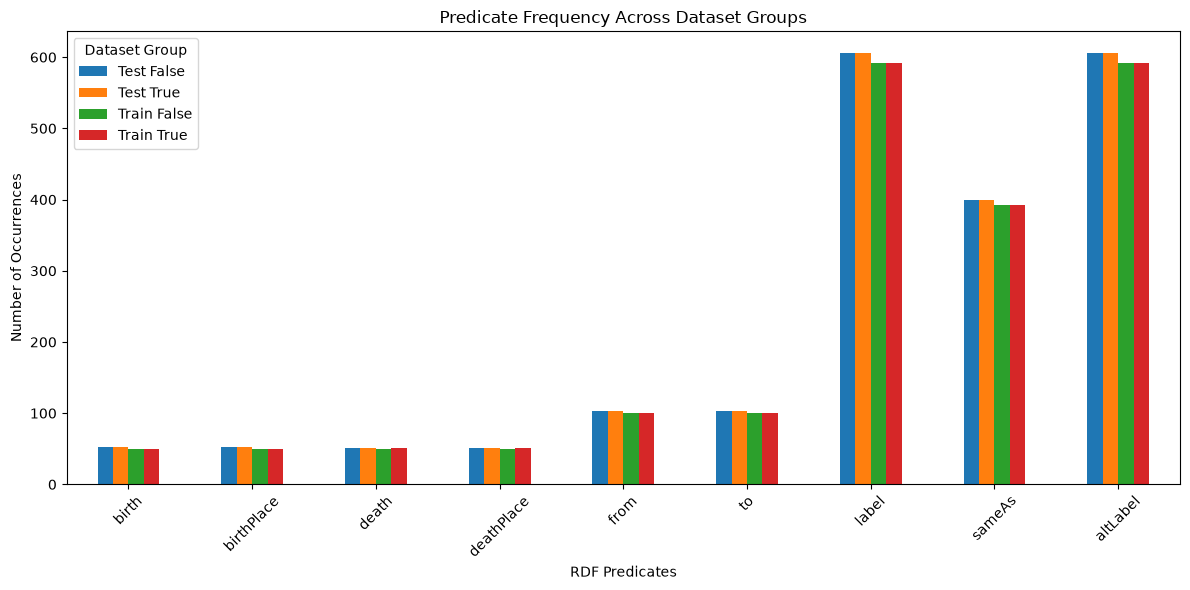

In [14]:
# Visualise predicate frequencies

predicate_comparison.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Predicate Frequency Across Dataset Groups")
plt.xlabel("RDF Predicates")
plt.ylabel("Number of Occurrences")
plt.xticks(rotation=45)
plt.legend(title="Dataset Group")
plt.tight_layout()

plt.show()

In [15]:
# Analyse subjects and objects in each dataset group

triple_structure_results = []

for group_name, folder in dataset_groups:

    subjects = set()
    objects = set()
    uri_objects = 0
    literal_objects = 0
    total_triples = 0

    for file in folder.glob("*.ttl"):

        graph = Graph()
        graph.parse(str(file), format="turtle")

        for subject, predicate, obj in graph:

            total_triples += 1
            subjects.add(subject)
            objects.add(obj)

            if isinstance(obj, rdflib.URIRef):
                uri_objects += 1

            elif isinstance(obj, rdflib.Literal):
                literal_objects += 1

    triple_structure_results.append({
        "Group": group_name,
        "Total Triples": total_triples,
        "Unique Subjects": len(subjects),
        "Unique Objects": len(objects),
        "URI Objects": uri_objects,
        "Literal Objects": literal_objects
    })

structure_df = pd.DataFrame(triple_structure_results)

display(structure_df)

,Group,Total Triples,Unique Subjects,Unique Objects,URI Objects,Literal Objects
0,Train True,1976,175,779,592,1384
1,Train False,1976,175,779,592,1384
2,Test True,2024,188,846,606,1418
3,Test False,2024,188,846,606,1418


### RDF Subject and Object Statistics

The analysis examined unique subjects, unique objects and the types of RDF objects in each dataset group.

The training groups each contain 175 unique subjects and 779 unique objects. The test groups each contain 188 unique subjects and 846 unique objects.

The object-type analysis identified URI objects and literal objects, with no blank-node objects in the analysed groups. Literal objects are more frequent than URI objects across all four groups.

The aggregate statistics are identical between the True and False categories within each dataset split.

In [16]:
# Analyse RDF object types

object_type_results = []

for group_name, folder in dataset_groups:

    object_types = {
        "URI": 0,
        "Literal": 0,
        "Blank Node": 0
    }

    for file in folder.glob("*.ttl"):

        graph = Graph()
        graph.parse(str(file), format="turtle")

        for subject, predicate, obj in graph:

            if isinstance(obj, rdflib.URIRef):
                object_types["URI"] += 1

            elif isinstance(obj, rdflib.Literal):
                object_types["Literal"] += 1

            elif isinstance(obj, rdflib.BNode):
                object_types["Blank Node"] += 1

    for object_type, count in object_types.items():

        object_type_results.append({
            "Group": group_name,
            "Object Type": object_type,
            "Count": count
        })

object_types_df = pd.DataFrame(object_type_results)

display(
    object_types_df.pivot(
        index="Object Type",
        columns="Group",
        values="Count"
    )
)

Group,Test False,Test True,Train False,Train True
Object Type,,,,
Blank Node,0,0,0,0
Literal,1418,1418,1384,1384
URI,606,606,592,592


In [17]:
# Inspect example RDF triples from each dataset group

for group_name, folder in dataset_groups:

    files = sorted(folder.glob("*.ttl"))

    if files:
        example_file = files[0]

        graph = Graph()
        graph.parse(str(example_file), format="turtle")

        print("\nDataset group:", group_name)
        print("Example file:", example_file.name)
        print("Total triples:", len(graph))
        print("\nFirst 8 RDF triples:")

        for i, (subject, predicate, obj) in enumerate(graph):
            if i == 8:
                break

            print("Subject:", subject)
            print("Predicate:", predicate)
            print("Object:", obj)
            print("--------------------------")


Dataset group: Train True
Example file: birth_0.ttl
Total triples: 20

First 8 RDF triples:
Subject: http://dbpedia.org/resource/George_Meade__1
Predicate: http://dbpedia.org/ontology/from
Object: 1815-12-31
--------------------------
Subject: http://dbpedia.org/resource/George_Meade
Predicate: http://www.w3.org/2004/02/skos/core#altLabel
Object: George Meade
--------------------------
Subject: http://dbpedia.org/resource/Cádiz
Predicate: http://www.w3.org/2004/02/skos/core#altLabel
Object: Cadix
--------------------------
Subject: http://dbpedia.org/resource/Cádiz
Predicate: http://www.w3.org/2004/02/skos/core#altLabel
Object: Cádiz
--------------------------
Subject: http://dbpedia.org/resource/George_Meade
Predicate: http://www.w3.org/2004/02/skos/core#altLabel
Object: George Gordon Meade
--------------------------
Subject: http://dbpedia.org/resource/Cádiz
Predicate: http://www.w3.org/2002/07/owl#sameAs
Object: http://fr.dbpedia.org/resource/Cadix
--------------------------
Subjec

### Inspection of Example RDF Graphs

Example RDF graphs from all four dataset groups were inspected to understand their structure and content. Each graph contains information represented through RDF triples consisting of a subject, predicate and object.

The examples contain entity information, relationships such as birth and birthplace, and supporting descriptions including labels, alternative labels and entity-equivalence links.

This inspection provides an initial understanding of how factual information is represented in the BPDP dataset.

In [18]:
# Inspect five triples from one example file per group

for group_name, folder in dataset_groups:

    files = sorted(folder.glob("*.ttl"))

    if files:
        example_file = files[0]

        graph = Graph()
        graph.parse(str(example_file), format="turtle")

        print("\nGroup:", group_name)
        print("File:", example_file.name)
        print("Total triples:", len(graph))

        for i, (subject, predicate, obj) in enumerate(graph):
            if i >= 5:
                break

            print(
                f"{i + 1}. "
                f"{subject.split('/')[-1]} "
                f"-- {predicate.split('/')[-1]} --> "
                f"{str(obj).split('/')[-1]}"
            )


Group: Train True
File: birth_0.ttl
Total triples: 20
1. George_Meade__1 -- from --> 1815-12-31
2. George_Meade -- core#altLabel --> George Meade
3. Cádiz -- core#altLabel --> Cadix
4. Cádiz -- core#altLabel --> Cádiz
5. George_Meade -- core#altLabel --> George Gordon Meade

Group: Train False
File: birth_103.ttl
Total triples: 20
1. George_Meade__1 -- from --> 1815-12-31
2. Philadelphia -- core#altLabel --> Philadelphia
3. George_Meade -- core#altLabel --> George Meade
4. George_Meade -- core#altLabel --> George Gordon Meade
5. Philadelphia -- rdf-schema#label --> Philadelphie

Group: Test True
File: birth_100.ttl
Total triples: 20
1. Ivan_Bunin -- birth --> Ivan_Bunin__1
2. Ivan_Bunin -- rdf-schema#label --> Ivan Bunin
3. Voronezh -- owl#sameAs --> Voronej
4. Ivan_Bunin__1 -- to --> 1870-10-22
5. Voronezh -- rdf-schema#label --> Woronesch

Group: Test False
File: birth_154.ttl
Total triples: 20
1. Ambrose -- owl#sameAs --> Ambrosius_von_Mailand
2. Milan -- core#altLabel --> Milan
3.

In [19]:
# Compare one True and False RDF example

true_file = train_true / "birth_0.ttl"
false_file = train_false / "birth_103.ttl"

true_graph = Graph()
false_graph = Graph()

true_graph.parse(str(true_file), format="turtle")
false_graph.parse(str(false_file), format="turtle")

true_triples = set(true_graph)
false_triples = set(false_graph)

common_triples = true_triples.intersection(false_triples)
true_only = true_triples - false_triples
false_only = false_triples - true_triples

print("Total True triples:", len(true_triples))
print("Total False triples:", len(false_triples))
print("Common triples:", len(common_triples))
print("Only in True:", len(true_only))
print("Only in False:", len(false_only))

print("\nTriples only in True:")
for triple in sorted(true_only, key=str):
    print(triple)

print("\nTriples only in False:")
for triple in sorted(false_only, key=str):
    print(triple)

Total True triples: 20
Total False triples: 20
Common triples: 11
Only in True: 9
Only in False: 9

Triples only in True:
(rdflib.term.URIRef('http://dbpedia.org/resource/Cádiz'), rdflib.term.URIRef('http://www.w3.org/2000/01/rdf-schema#label'), rdflib.term.Literal('Cadix', lang='fr'))
(rdflib.term.URIRef('http://dbpedia.org/resource/Cádiz'), rdflib.term.URIRef('http://www.w3.org/2000/01/rdf-schema#label'), rdflib.term.Literal('Cádiz', lang='de'))
(rdflib.term.URIRef('http://dbpedia.org/resource/Cádiz'), rdflib.term.URIRef('http://www.w3.org/2000/01/rdf-schema#label'), rdflib.term.Literal('Cádiz', lang='en'))
(rdflib.term.URIRef('http://dbpedia.org/resource/Cádiz'), rdflib.term.URIRef('http://www.w3.org/2002/07/owl#sameAs'), rdflib.term.URIRef('http://de.dbpedia.org/resource/Cádiz'))
(rdflib.term.URIRef('http://dbpedia.org/resource/Cádiz'), rdflib.term.URIRef('http://www.w3.org/2002/07/owl#sameAs'), rdflib.term.URIRef('http://fr.dbpedia.org/resource/Cadix'))
(rdflib.term.URIRef('http:/

### True and False RDF Graph Comparison

A comparison of two example RDF graphs, `birth_0.ttl` (Train True) and `birth_103.ttl` (Train False), showed that both graphs contain 20 triples. They share 11 triples, while each contains 9 unique triples.

The main factual difference concerns the `birthPlace` relationship: the True example associates George Meade with Cádiz, whereas the False example associates him with Philadelphia. Most of the remaining differences concern descriptive information about these locations, including labels, alternative labels and entity-equivalence links.

This example demonstrates that graphs with identical triple counts and similar predicate structures can represent different factual information.

In [20]:
# Compare RDF graphs from the first 10 files in each class

comparison_results = []

true_files = sorted(train_true.glob("*.ttl"))[:10]
false_files = sorted(train_false.glob("*.ttl"))[:10]

for true_file, false_file in zip(true_files, false_files):

    true_graph = Graph()
    false_graph = Graph()

    true_graph.parse(str(true_file), format="turtle")
    false_graph.parse(str(false_file), format="turtle")

    true_triples = set(true_graph)
    false_triples = set(false_graph)

    common = true_triples & false_triples
    true_only = true_triples - false_triples
    false_only = false_triples - true_triples

    comparison_results.append({
        "True File": true_file.name,
        "False File": false_file.name,
        "Common Triples": len(common),
        "True-only Triples": len(true_only),
        "False-only Triples": len(false_only)
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df)

,True File,False File,Common Triples,True-only Triples,False-only Triples
0,birth_0.ttl,birth_103.ttl,11,9,9
1,birth_1.ttl,birth_104.ttl,11,9,9
2,birth_10.ttl,birth_105.ttl,0,20,20
3,birth_11.ttl,birth_106.ttl,0,20,20
4,birth_12.ttl,birth_107.ttl,0,17,20
5,birth_13.ttl,birth_108.ttl,0,20,17
6,birth_14.ttl,birth_109.ttl,0,20,20
7,birth_15.ttl,birth_110.ttl,0,20,20
8,birth_16.ttl,birth_111.ttl,0,20,20
9,birth_18.ttl,birth_112.ttl,0,20,20


### Comparison of Multiple True and False RDF Graphs

Ten RDF graphs from the training True category were compared with ten graphs from the training False category. The comparison measured the number of common triples and the triples unique to each graph.

The results show that some comparisons contain common triples, while others have no identical triples. This demonstrates variation in the amount of shared information between the selected graphs.

However, the files were paired according to their sorted order rather than verified matching examples. Therefore, this comparison is exploratory and does not establish a general difference between the True and False classes.

In [21]:
# Analyse the distribution of triple counts

triple_distribution = []

for group_name, folder in dataset_groups:
    for file in folder.glob("*.ttl"):

        graph = Graph()
        graph.parse(str(file), format="turtle")

        triple_distribution.append({
            "Group": group_name,
            "File": file.name,
            "Triple Count": len(graph)
        })

triple_df = pd.DataFrame(triple_distribution)

display(
    triple_df.groupby(["Group", "Triple Count"])
    .size()
    .unstack(fill_value=0)
)

Triple Count,14,17,20
Group,,,
Test False,3,6,94
Test True,3,6,94
Train False,2,4,94
Train True,2,4,94


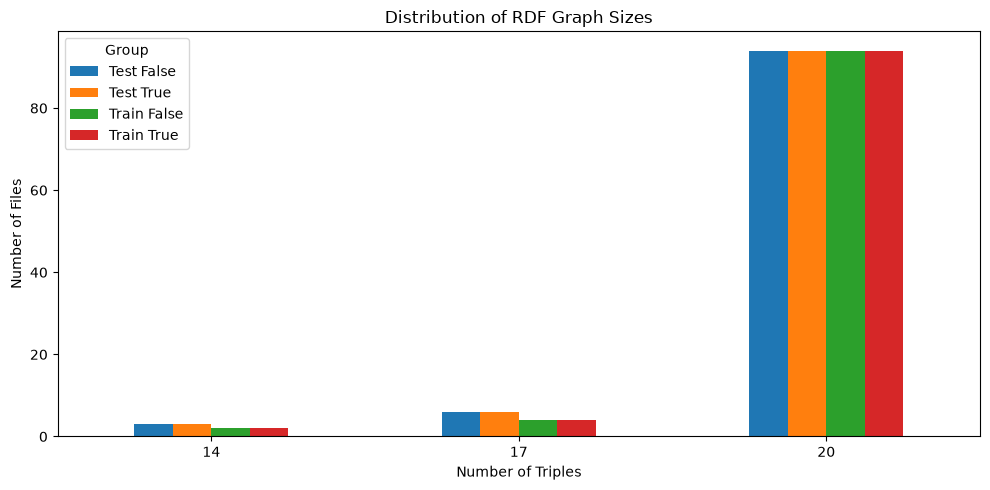

In [22]:
triple_distribution_table = triple_df.pivot_table(
    index="Triple Count",
    columns="Group",
    values="File",
    aggfunc="count",
    fill_value=0
)

triple_distribution_table.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Distribution of RDF Graph Sizes")
plt.xlabel("Number of Triples")
plt.ylabel("Number of Files")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### RDF Graph Size Distribution

The analysis of all 406 RDF files showed that the graphs contain 14, 17, or 20 triples. Most graphs contain 20 triples (94 files in each dataset group).

The training groups have identical distributions: 2 files contain 14 triples, 4 contain 17 triples, and 94 contain 20 triples. The test groups also have identical distributions: 3 files contain 14 triples, 6 contain 17 triples, and 94 contain 20 triples.

This indicates that graph size is balanced between the True and False classes in both training and testing datasets. Therefore, the number of triples alone is unlikely to be a useful feature for distinguishing factual and false examples.